Number of training documents: 11314
Number of testing documents : 7532
Number of classes            : 20

Performance Comparison:
         Model  Accuracy  Precision   Recall  F1 Score
Multinomial NB  0.651089   0.634470 0.636933  0.617859
  Bernoulli NB  0.485130   0.616678 0.469434  0.467865

Results rounded to 3 decimal places:
                Accuracy  Precision  Recall  F1 Score
Model                                                
Multinomial NB     0.651      0.634   0.637     0.618
Bernoulli NB       0.485      0.617   0.469     0.468

Best Model for Each Metric:
Accuracy: Multinomial NB (0.651)
Precision: Multinomial NB (0.634)
Recall: Multinomial NB (0.637)
F1 Score: Multinomial NB (0.618)


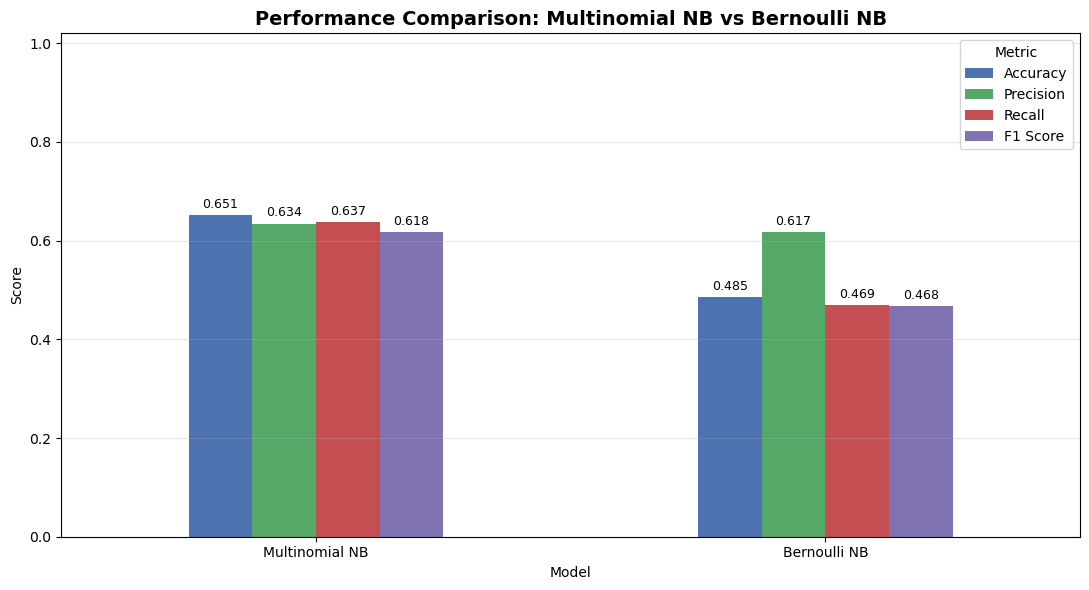

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB, BernoulliNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

train_data = fetch_20newsgroups(
    subset="train",
    remove=("headers", "footers", "quotes")
)

test_data = fetch_20newsgroups(
    subset="test",
    remove=("headers", "footers", "quotes")
)

X_train_text = train_data.data
y_train = train_data.target

X_test_text = test_data.data
y_test = test_data.target

class_names = train_data.target_names

print("Number of training documents:", len(X_train_text))
print("Number of testing documents :", len(X_test_text))
print("Number of classes            :", len(class_names))

vectorizer = CountVectorizer(
    stop_words="english",
    min_df=2
)

X_train_mnb = vectorizer.fit_transform(X_train_text)
X_test_mnb = vectorizer.transform(X_test_text)

mnb = MultinomialNB()
mnb.fit(X_train_mnb, y_train)

y_pred_mnb = mnb.predict(X_test_mnb)

binary_vectorizer = CountVectorizer(
    stop_words="english",
    min_df=2,
    binary=True
)

X_train_bnb = binary_vectorizer.fit_transform(X_train_text)
X_test_bnb = binary_vectorizer.transform(X_test_text)

bnb = BernoulliNB()
bnb.fit(X_train_bnb, y_train)

y_pred_bnb = bnb.predict(X_test_bnb)

results = pd.DataFrame({
    "Model": [
        "Multinomial NB",
        "Bernoulli NB"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_mnb),
        accuracy_score(y_test, y_pred_bnb)
    ],
    "Precision": [
        precision_score(
            y_test,
            y_pred_mnb,
            average="macro",
            zero_division=0
        ),
        precision_score(
            y_test,
            y_pred_bnb,
            average="macro",
            zero_division=0
        )
    ],
    "Recall": [
        recall_score(
            y_test,
            y_pred_mnb,
            average="macro",
            zero_division=0
        ),
        recall_score(
            y_test,
            y_pred_bnb,
            average="macro",
            zero_division=0
        )
    ],
    "F1 Score": [
        f1_score(
            y_test,
            y_pred_mnb,
            average="macro",
            zero_division=0
        ),
        f1_score(
            y_test,
            y_pred_bnb,
            average="macro",
            zero_division=0
        )
    ]
})

print("\nPerformance Comparison:")
print(results.to_string(index=False))

print("\nResults rounded to 3 decimal places:")
print(results.set_index("Model").round(3))

print("\nBest Model for Each Metric:")

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

for metric in metrics:
    best_model = results.loc[
        results[metric].idxmax(),
        "Model"
    ]

    best_score = results.loc[
        results[metric].idxmax(),
        metric
    ]

    print(f"{metric}: {best_model} ({best_score:.3f})")

results_metrics = results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
]

ax = results_metrics.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"]
)

plt.title(
    "Performance Comparison: Multinomial NB vs Bernoulli NB",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.02)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

plt.tight_layout()
plt.show()